# Homogeneous emitting cylinder

A uniform cylinder ($r < 1$, $\rho\kappa = 10$, $aT^4 = 1$) in vacuum on a Cartesian mesh, the
2-D analogue of the homogeneous sphere of the IDORT paper (Ma et al. 2025, sec. 4.1.2) and
Jiang (2021, ApJS 253, 49, sec. 4.6), with the production keys (`decks/idort_cylinder.athinput`).
The box is $[-4, 4]^2$, periodic in $y$ (a row of cylinders, period 8). E and the flux along
$y = 0$ are compared with the exact transport solution (`ref/idort_cylinder_exact.npz`).
Criteria: L1 of E inside and outside and of the energy flux and the face momentum outside within 5 % of the reference values
(`ref/references.json`). Code units.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
ATHENAK = os.path.abspath(os.environ.get('ATHENAK', '../../athenak'))   # your athenak checkout
sys.path.insert(0, os.path.join(ATHENAK, 'tests/vet_clean/notebooks'))
import nbutil as nb                        # nb.suite, nb.verdict, nb.vett (readers), nb.rt (run_tests)

# the athena binary (a CPU build, default the one tests/vet_clean/run_tests.sh builds)
EXE = os.path.abspath(os.environ.get('ATHENA_EXE', os.path.join(ATHENAK, 'build_tests/src/athena')))
# where the runs go; a test whose run is already there is only loaded, not rerun
WORK = os.path.abspath(os.environ.get('VET_NB_WORKDIR', 'runs'))
THREADS = int(os.environ.get('VET_NB_THREADS', '4'))   # OpenMP threads per run
nb.style()
print('binary', os.path.relpath(EXE), '\nruns  ', os.path.relpath(WORK))

binary ../../athenak/build_tests/src/athena 
runs   runs


In [2]:
TESTS = ['idort_cylinder']
res = {t: nb.suite(t, EXE, WORK, THREADS) for t in TESTS}
vett, rt = nb.vett, nb.rt

loading the existing run runs/idort_cylinder


## Emitting cylinder

E, the energy flux $\Phi_x/c$ (`vet_phi1`) and the face momentum $F_x/c$ (`vet_f1`) along
$y = 0$ against the exact transport solution. Outside the cylinder E agrees to 1.1 % and the
energy flux to 1.2 % (`F_out`); the face momentum is about 20 % above the exact flux
(`FH_out`, a regression reference).

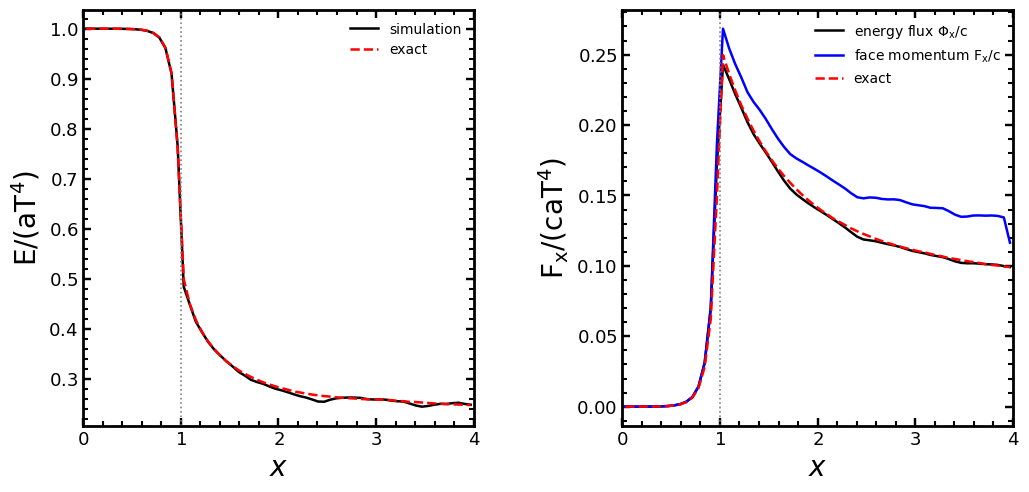

PASS idort_cylinder   criterion {"near": {"E_in": [0.000531, 0.05], "E_out": [0.0111, 0.05], "F_out": [0.0116, 0.05], "FH_out": [0.203, 0.05]}}


True

In [3]:
LB, LG = 20, 12   # label sizes
# ---- cylinder
d = os.path.join(WORK, 'idort_cylinder', 'run'); m, (x1, x2, _) = vett.last_bin(d, 'vet'), vett.cell_centres(d); ex = np.load(os.path.join(nb.SUITE, 'ref', 'idort_cylinder_exact.npz')); cl = float(vett.parse_deck_text(open(os.path.join(d, 'in.athinput')).read())['rad_vet']['c_light'])
j, s = np.argsort(np.abs(x2))[:2], x1 > 0
fig, ax = plt.subplots(1, 2, figsize=(12, 5.4), gridspec_kw={'wspace': 0.38})
ax[0].plot(x1[s], m['vet_e'][0][j].mean(axis=0)[s], 'k-', label='simulation'); ax[0].plot(ex['x'], ex['E'], 'r--', label='exact')
ax[1].plot(x1[s], m['vet_phi1'][0][j].mean(axis=0)[s]/cl, 'k-', label=r'energy flux $\rm \Phi_x / c$'); ax[1].plot(x1[s], m['vet_f1'][0][j].mean(axis=0)[s]/cl, 'b-', label=r'face momentum $\rm F_x / c$'); ax[1].plot(ex['x'], ex['F'], 'r--', label='exact')
for a, y in zip(ax, (r'$\rm E / (a T^4)$', r'$\rm F_x / (c a T^4)$')):
    a.axvline(1.0, c='0.5', ls=':', lw=1.2); a.set_xlabel(r'$x$', fontsize=LB); a.set_ylabel(y, fontsize=LB); a.set_xlim(0, 4); a.legend(fontsize=LG - 2, loc='upper right')
plt.show()
nb.verdict('idort_cylinder', res['idort_cylinder'])